# Modelado y evaluación


**Antes de ejecutar:** `python src/preprocess.py` (genera `data/processed/`, que no se sube a Git).

### 0. Preparación en Google Colab (omitir si se trabaja en local con el repo clonado)

En Colab el notebook corre aislado: **no tiene** `src/preprocess.py` ni los datos. Esta celda clona el repo, entra en su carpeta y ejecuta `preprocess.py` para generar `data/processed/`.


In [16]:
import os, subprocess, sys

if "google.colab" in sys.modules and not os.path.exists("src/preprocess.py"):
    REPO_URL = "https://github.com/Bootcamp-DA-P3/Proyecto_8_Clasificacion_Lena_Tania_Franco.git"
    BRANCH = "dev"   # cambia a "main" si preprocess.py aún no está en dev
    subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, "repo_p8"], check=True)
    os.chdir("repo_p8")

# Generar data/processed/ si aún no existe (requiere el CSV en data/raw/)
if os.path.exists("src/preprocess.py") and not os.path.exists("data/processed/train_raw.csv"):
    subprocess.run([sys.executable, "src/preprocess.py"], check=True)

print("Directorio de trabajo:", os.getcwd())
print("preprocess.py:", os.path.exists("src/preprocess.py"),
      "| train_raw.csv:", os.path.exists("data/processed/train_raw.csv"))

Directorio de trabajo: /content/repo_p8
preprocess.py: True | train_raw.csv: True


## 1. Configuración e importaciones
Preparamos el entorno: **ubicamos la raíz del repo** para importar **src.preprocess** y reutilizamos su preprocesado (columnas, target, RANDOM_STATE=42). Fijamos las **constantes del equipo**: POS_LABEL = 0 (la clase de interés es "sin cuenta", la minoritaria, y las métricas se calculan sobre ella) y MAX_GAP = 0.05 (overfitting máximo, medido como diferencia de F1 entre train y test). Los parámetros,  p. ej. 30000 para pruebas rápidas de la validación cruzada, permiten ejecuciones rápidas en pruebas. **LightGBM y XGBoost** son opcionales.



In [30]:
import sys, json, time, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform

from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             brier_score_loss, confusion_matrix, f1_score, make_scorer,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

# --- raíz del repo e importación del preprocesado (src/preprocess.py) ---
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.preprocess import (NUM_FEATURES, BIN_FEATURES, CAT_FEATURES, TARGET, RANDOM_STATE,
                            PROCESSED_DIR, construir_preprocesador)

# --- convenciones del equipo ---
FEATURES = NUM_FEATURES + BIN_FEATURES + CAT_FEATURES
POS_LABEL = 0          # clase de interés: SIN cuenta
MAX_GAP = 0.05         # overfitting máximo permitido (F1 train - F1 test)
MUESTRA = None         # p. ej. 30000 para pruebas rápidas de la validación cruzada
# --- tuning (la parte más lenta del notebook) ---
EJECUTAR_TUNING = True   # False = saltar el tuning y usar los hiperparámetros por defecto
N_ITER_TUNING = 15       # configuraciones que prueba (25 = más fino, más lento)
TUNING_FOLDS = 3         # folds de la búsqueda (5 = más fino, más lento)
TUNING_MUESTRA = 40000   # filas de train usadas SOLO para buscar (None = todas)

# --- carpetas de salida ---
TABLES_DIR = ROOT / "reports" / "tables"
FIGURES_DIR = ROOT / "reports" / "figures"
MODELS_DIR = ROOT / "models"
for d in (TABLES_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
print("Raíz del repo:", ROOT)
print("Features:", FEATURES)

Raíz del repo: /content/repo_p8
Features: ['age', 'educ', 'inc_q', 'female', 'emp_in', 'urban', 'internet_use', 'regionwb', 'economycode']


## 2. Carga de datos

`preprocess.py` genera **dos versiones** del split:

| Archivo | Contenido | ¿Lo usamos? |
|---|---|---|
| `train_raw.csv` / `test_raw.csv` | Datos limpios **sin codificar** (female/emp_in/urban ya en 0/1, regionwb y economycode aún como texto) + `account` | **Sí** |
| `train.csv` / `test.csv` | Ya codificados y escalados | No (solo para inspección) |

Cargamos train_raw.csv y test_raw.csv (split 80/20 ya hecho en preprocess.py). Usamos los datos sin codificar porque el preprocesador va dentro del Pipeline y así se ajusta solo con el train de cada fold, evitando fuga de información; el test se reserva para la medición final.
La división 80/20 estratificada con `random_state=42` ya está hecha en preprocess. El test no se usa para decidir (modelo, parámetros ni umbral): solo para medir.


In [18]:
def cargar_split():
    """Lee train_raw.csv y test_raw.csv y devuelve X_train, y_train, X_test, y_test."""
    tr, te = PROCESSED_DIR / "train_raw.csv", PROCESSED_DIR / "test_raw.csv"
    if not (tr.exists() and te.exists()):
        raise FileNotFoundError("Faltan train_raw.csv / test_raw.csv. "
                                "Ejecuta primero: python src/preprocess.py")
    train, test = pd.read_csv(tr), pd.read_csv(te)
    return train[FEATURES], train[TARGET], test[FEATURES], test[TARGET]


X_train, y_train, X_test, y_test = cargar_split()

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print("\nProporción de clases en train (0 = sin cuenta, 1 = con cuenta):")
print(y_train.value_counts(normalize=True).round(3).to_string())
print("\nNulos por columna en train:")
print(X_train.isna().mean().round(4).to_string())
X_train.head()

X_train: (115272, 9) | X_test: (28818, 9)

Proporción de clases en train (0 = sin cuenta, 1 = con cuenta):
account
1    0.738
0    0.262

Nulos por columna en train:
age             0.0000
educ            0.0041
inc_q           0.0068
female          0.0000
emp_in          0.0277
urban           0.0173
internet_use    0.0000
regionwb        0.0000
economycode     0.0000


,age,educ,inc_q,female,emp_in,urban,internet_use,regionwb,economycode
0,27,2.0,5.0,0,0.0,0.0,1,Middle East & North Africa (excluding high inc...,EGY
1,43,3.0,1.0,1,1.0,1.0,1,East Asia & Pacific (excluding high income),IDN
2,30,2.0,2.0,0,0.0,0.0,1,Sub-Saharan Africa (excluding high income),MOZ
3,29,3.0,3.0,0,1.0,NaN,1,High income,PRT
4,19,2.0,4.0,1,0.0,0.0,1,Middle East & North Africa (excluding high inc...,LBY


## 3. Funciones auxiliares y Baseline

Definimos las funciones reutilizables: un Pipeline (preprocesador + modelo), la probabilidad de "sin cuenta" y su conversión a clase según un umbral, el cálculo de métricas sobre esa clase (precision, recall, F1, ROC-AUC, PR-AUC, Brier y accuracy) y el control de overfitting (gap = F1_train − F1_test < 0,05). También una función que busca el umbral óptimo usando solo el train.

In [19]:
def crear_pipeline(clf):
    """Preprocesador + clasificador. Se re-ajusta en cada fold de la CV (sin fuga)."""
    return Pipeline([("prep", construir_preprocesador()), ("modelo", clf)])


def p_sin_cuenta(pipe, X):
    """Probabilidad de la clase 0 (sin cuenta)."""
    return pipe.predict_proba(X)[:, list(pipe.classes_).index(POS_LABEL)]


def predecir_clase(p0, umbral=0.5):
    """0 = sin cuenta si P(sin cuenta) >= umbral; 1 = con cuenta."""
    return np.where(np.asarray(p0) >= umbral, 0, 1)


def metricas(y_true, p0, umbral=0.5):
    y_true = np.asarray(y_true)
    y_pred = predecir_clase(p0, umbral)
    y_excl = (y_true == POS_LABEL).astype(int)      # 1 = sin cuenta (para ROC y PR)
    return {
        "umbral": float(umbral),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_sin_cuenta": precision_score(y_true, y_pred, pos_label=POS_LABEL, zero_division=0),
        "recall_sin_cuenta": recall_score(y_true, y_pred, pos_label=POS_LABEL, zero_division=0),
        "f1_sin_cuenta": f1_score(y_true, y_pred, pos_label=POS_LABEL, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_excl, p0),
        "pr_auc": average_precision_score(y_excl, p0),
        "brier": brier_score_loss(y_excl, p0),
    }


def evaluar_overfitting(pipe, Xtr, ytr, Xte, yte, umbral=0.5):
    """Métricas en train y test + gap de F1 (criterio del equipo: gap < 0.05)."""
    m_tr = metricas(ytr, p_sin_cuenta(pipe, Xtr), umbral)
    m_te = metricas(yte, p_sin_cuenta(pipe, Xte), umbral)
    gap = m_tr["f1_sin_cuenta"] - m_te["f1_sin_cuenta"]
    return {"train": m_tr, "test": m_te, "gap_f1": gap,
            "gap_accuracy": m_tr["accuracy"] - m_te["accuracy"],
            "overfitting_ok": bool(gap < MAX_GAP)}


def mejor_umbral_f1(y_true, p0):
    """Umbral que maximiza el F1 de 'sin cuenta' (usar solo con predicciones de TRAIN)."""
    y_excl = (np.asarray(y_true) == POS_LABEL).astype(int)
    prec, rec, thr = precision_recall_curve(y_excl, p0)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[int(np.argmax(f1))])


def guardar_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=float, ensure_ascii=False))


# scorers para validación cruzada (mismas métricas, con pos_label=0)
SCORING = {
    "f1_sin_cuenta": make_scorer(f1_score, pos_label=POS_LABEL),
    "recall_sin_cuenta": make_scorer(recall_score, pos_label=POS_LABEL),
    "precision_sin_cuenta": make_scorer(precision_score, pos_label=POS_LABEL, zero_division=0),
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
}

El baseline es una regresión logística con class_weight="balanced" (para no ignorar la clase minoritaria "sin cuenta") y max_iter=1000 (para asegurar la convergencia). Es el punto de referencia que los modelos más complejos deben superar, evaluado en train y test con su control de overfitting.


In [20]:
pipe_base = crear_pipeline(LogisticRegression(class_weight="balanced", max_iter=1000,
                                               random_state=RANDOM_STATE))
t0 = time.time()
pipe_base.fit(X_train, y_train)
res_base = evaluar_overfitting(pipe_base, X_train, y_train, X_test, y_test)
res_base["tiempo_ajuste_s"] = time.time() - t0
guardar_json(res_base, TABLES_DIR / "baseline.json")

tabla_base = pd.DataFrame({"train": res_base["train"], "test": res_base["test"]}).drop("umbral")
display(tabla_base.round(4))
print(f"Overfitting (F1_train - F1_test) = {res_base['gap_f1']:.4f} -> "
      f"{'OK (<5%)' if res_base['overfitting_ok'] else 'SUPERA 5%'}")

,train,test
accuracy,0.7773,0.7756
precision_sin_cuenta,0.5507,0.5484
recall_sin_cuenta,0.8173,0.8159
f1_sin_cuenta,0.6580,0.6559
f1_macro,0.7465,0.7447
roc_auc,0.8716,0.8696
pr_auc,0.6911,0.6887
brier,0.1498,0.1510


Overfitting (F1_train - F1_test) = 0.0021 -> OK (<5%)


## 4. Verificar overfitting < 5%

Medimos el overfitting como la diferencia de F1 entre train y test (debe ser menor al 5%) y lo ilustramos con un árbol de distintas profundidades: el árbol sin límite memoriza el train, y por eso limitamos la complejidad de todos los modelos y filtramos el tuning por este criterio.


In [21]:
filas = []
for prof in [3, 6, 10, None]:
    clf = DecisionTreeClassifier(max_depth=prof, class_weight="balanced", random_state=RANDOM_STATE)
    p = crear_pipeline(clf).fit(X_train, y_train)
    r = evaluar_overfitting(p, X_train, y_train, X_test, y_test)
    filas.append({"max_depth": "sin límite" if prof is None else prof,
                  "f1_train": r["train"]["f1_sin_cuenta"], "f1_test": r["test"]["f1_sin_cuenta"],
                  "gap_f1": r["gap_f1"], "cumple_<5%": r["overfitting_ok"]})
tabla_overfit = pd.DataFrame(filas)
tabla_overfit.to_csv(TABLES_DIR / "demo_overfitting_arbol.csv", index=False)
display(tabla_overfit.round(4))

,max_depth,f1_train,f1_test,gap_f1,cumple_<5%
0,3,0.5755,0.5742,0.0013,True
1,6,0.6150,0.6106,0.0045,True
2,10,0.6486,0.6322,0.0164,True
3,sin límite,0.9448,0.5621,0.3827,False


## 5. Comparar modelos

Entrenamos varios algoritmos en las mismas condiciones (mismo preprocesador, mismo train y mismo test) y los comparamos:

**Catálogo (`catalogo_modelos`)** — qué es cada uno y por qué esos hiperparámetros:

| Modelo | Idea | Controles de complejidad usados |
|---|---|---|
| `logreg` | Lineal, interpretable (el baseline) | — |
| `arbol` | Reglas "si-entonces" encadenadas | `max_depth=8`, `min_samples_leaf=100` |
| `random_forest` | Muchos árboles en paralelo que votan (ensemble *bagging*) | 200 árboles, `max_depth=12`, `min_samples_leaf=50` |
| `hist_gb` | Gradient Boosting: árboles en secuencia, cada uno corrige errores del anterior (ensemble *boosting*) | `learning_rate=0.1`, `max_depth=6`, `l2_regularization=1`, `min_samples_leaf=100` |
| `lightgbm`, `xgboost` | Boosting optimizados (solo si están instalados) | `min_child_samples`/`min_child_weight`, `reg_lambda` |

Un min_samples_leaf alto impide memorizar casos individuales. Usamos class_weight="balanced" en los modelos que lo admiten y random_state=42 en todos. XGBoost no tiene class_weight, así que su desbalance se compensa con el umbral (sección 8); por eso comparamos sobre todo por ROC-AUC, que no depende del umbral, y usamos F1 y recall como apoyo.

La tabla muestra el rendimiento en test solo como referencia. La elección del modelo se hace con la validación cruzada (sección 6): el de mayor ROC-AUC entre los que cumplen overfitting < 5%, y si hay empate técnico, el más simple.

In [22]:
def catalogo_modelos():
    modelos = {
        "logreg": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
        "arbol": DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, class_weight="balanced",
                                        random_state=RANDOM_STATE),
        "random_forest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50,
                                                class_weight="balanced", n_jobs=-1,
                                                random_state=RANDOM_STATE),
        "hist_gb": HistGradientBoostingClassifier(max_depth=6, learning_rate=0.1, max_iter=200,
                                                  l2_regularization=1.0, min_samples_leaf=100,
                                                  class_weight="balanced", random_state=RANDOM_STATE),
    }
    if LGBMClassifier is not None:
        modelos["lightgbm"] = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                             min_child_samples=100, reg_lambda=1.0,
                                             class_weight="balanced", random_state=RANDOM_STATE,
                                             n_jobs=-1, verbose=-1)
    if XGBClassifier is not None:
        modelos["xgboost"] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                                           min_child_weight=20, reg_lambda=2.0, subsample=0.8,
                                           colsample_bytree=0.8, tree_method="hist",
                                           random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss")
    return modelos


filas = []
for nombre, clf in catalogo_modelos().items():
    t0 = time.time()
    pipe = crear_pipeline(clf).fit(X_train, y_train)
    r = evaluar_overfitting(pipe, X_train, y_train, X_test, y_test)
    fila = {"modelo": nombre, "tiempo_s": round(time.time() - t0, 1)}
    for k in ["accuracy", "precision_sin_cuenta", "recall_sin_cuenta", "f1_sin_cuenta", "roc_auc", "pr_auc"]:
        fila[f"{k}_test"] = r["test"][k]
    fila.update(f1_train=r["train"]["f1_sin_cuenta"], gap_f1=r["gap_f1"], overfitting_ok=r["overfitting_ok"])
    filas.append(fila)
    print(f"{nombre:14s} AUC={fila['roc_auc_test']:.4f}  F1={fila['f1_sin_cuenta_test']:.4f}  "
          f"gap={fila['gap_f1']:.4f}  {'OK' if fila['overfitting_ok'] else 'OVERFIT'}")

tabla_comp = pd.DataFrame(filas).sort_values("roc_auc_test", ascending=False).reset_index(drop=True)
tabla_comp.to_csv(TABLES_DIR / "comparacion_modelos.csv", index=False)
display(tabla_comp.round(4))

logreg         AUC=0.8696  F1=0.6559  gap=0.0021  OK
arbol          AUC=0.8325  F1=0.6206  gap=0.0041  OK
random_forest  AUC=0.8516  F1=0.6316  gap=0.0032  OK
hist_gb        AUC=0.8770  F1=0.6675  gap=0.0029  OK
lightgbm       AUC=0.8811  F1=0.6684  gap=0.0070  OK
xgboost        AUC=0.8737  F1=0.6177  gap=0.0095  OK


,modelo,tiempo_s,accuracy_test,precision_sin_cuenta_test,recall_sin_cuenta_test,f1_sin_cuenta_test,roc_auc_test,pr_auc_test,f1_train,gap_f1,overfitting_ok
0,lightgbm,8.0,0.7826,0.5569,0.8358,0.6684,0.8811,0.7163,0.6754,0.0070,True
1,hist_gb,37.6,0.7827,0.5573,0.8321,0.6675,0.8770,0.7083,0.6704,0.0029,True
2,xgboost,10.7,0.8201,0.6975,0.5543,0.6177,0.8737,0.7053,0.6272,0.0095,True
3,logreg,8.8,0.7756,0.5484,0.8159,0.6559,0.8696,0.6887,0.6580,0.0021,True
4,random_forest,36.8,0.7499,0.5146,0.8174,0.6316,0.8516,0.6642,0.6347,0.0032,True
5,arbol,2.9,0.7526,0.5189,0.7718,0.6206,0.8325,0.6014,0.6247,0.0041,True


## 6. Validación cruzada K-Fold estratificada

Validamos los modelos con K-Fold estratificado de 5 folds, solo sobre train, para medir su rendimiento medio, su estabilidad (desviación) y su overfitting sin depender de un único split. Con esta tabla elegimos el modelo final, y el test queda reservado para la medición final.

In [23]:
if MUESTRA:
    idx = X_train.sample(min(MUESTRA, len(X_train)), random_state=RANDOM_STATE).index
    Xcv, ycv = X_train.loc[idx], y_train.loc[idx]
else:
    Xcv, ycv = X_train, y_train

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

filas = []
for nombre, clf in catalogo_modelos().items():
    r = cross_validate(crear_pipeline(clf), Xcv, ycv, cv=cv, scoring=SCORING,
                       return_train_score=True, n_jobs=-1)
    fila = {"modelo": nombre}
    for k in SCORING:
        fila[f"{k}_val"] = r[f"test_{k}"].mean()
        fila[f"{k}_val_std"] = r[f"test_{k}"].std()
    fila["f1_train"] = r["train_f1_sin_cuenta"].mean()
    fila["gap_f1"] = fila["f1_train"] - fila["f1_sin_cuenta_val"]
    fila["overfitting_ok"] = fila["gap_f1"] < MAX_GAP
    filas.append(fila)
    print(f"{nombre:14s} AUC={fila['roc_auc_val']:.4f} ± {fila['roc_auc_val_std']:.4f}  "
          f"F1={fila['f1_sin_cuenta_val']:.4f}  gap={fila['gap_f1']:.4f}")

tabla_cv = pd.DataFrame(filas).sort_values("roc_auc_val", ascending=False).reset_index(drop=True)
tabla_cv.to_csv(TABLES_DIR / "validacion_cruzada.csv", index=False)
display(tabla_cv.round(4))

logreg         AUC=0.8705 ± 0.0019  F1=0.6569  gap=0.0014
arbol          AUC=0.8350 ± 0.0031  F1=0.6148  gap=0.0031
random_forest  AUC=0.8519 ± 0.0021  F1=0.6329  gap=0.0019
hist_gb        AUC=0.8772 ± 0.0019  F1=0.6655  gap=0.0059
lightgbm       AUC=0.8808 ± 0.0017  F1=0.6683  gap=0.0087
xgboost        AUC=0.8741 ± 0.0021  F1=0.6211  gap=0.0067


,modelo,f1_sin_cuenta_val,f1_sin_cuenta_val_std,recall_sin_cuenta_val,recall_sin_cuenta_val_std,precision_sin_cuenta_val,precision_sin_cuenta_val_std,roc_auc_val,roc_auc_val_std,accuracy_val,accuracy_val_std,f1_train,gap_f1,overfitting_ok
0,lightgbm,0.6683,0.0021,0.8311,0.0036,0.5589,0.0024,0.8808,0.0017,0.7837,0.0017,0.6770,0.0087,True
1,hist_gb,0.6655,0.0029,0.8235,0.0054,0.5584,0.0031,0.8772,0.0019,0.7829,0.0022,0.6714,0.0059,True
2,xgboost,0.6211,0.0057,0.5547,0.0058,0.7056,0.0060,0.8741,0.0021,0.8226,0.0025,0.6278,0.0067,True
3,logreg,0.6569,0.0034,0.8157,0.0040,0.5498,0.0038,0.8705,0.0019,0.7766,0.0028,0.6583,0.0014,True
4,random_forest,0.6329,0.0018,0.8199,0.0044,0.5154,0.0020,0.8519,0.0021,0.7507,0.0016,0.6348,0.0019,True
5,arbol,0.6148,0.0045,0.8102,0.0293,0.4963,0.0164,0.8350,0.0031,0.7337,0.0139,0.6179,0.0031,True


## 7. Tuning de hiperparámetros

**Objetivo:** encontrar los hiperparámetros del mejor modelo sin tocar el test.

Buscamos los hiperparámetros del mejor modelo de la validación cruzada (sección 6) con RandomizedSearchCV, que prueba combinaciones sorteadas de rangos acotados y solo usa el train. De todas las configuraciones nos quedamos con las de gap < 0,05 entre train y validación, y elegimos la de mayor ROC-AUC; si ninguna cumple, se toma la de menor gap.

Por velocidad, la búsqueda usa una submuestra de 40.000 filas, 3 folds y 15 configuraciones, mientras que el modelo final (sección 8) se entrena con todo el train. Las salidas son tuning_resultados.csv y mejores_parametros.json.



In [24]:
ESPACIOS = {
    "logreg": {"modelo__C": loguniform(1e-3, 1e2)},
    "arbol": {"modelo__max_depth": randint(3, 12), "modelo__min_samples_leaf": randint(50, 500)},
    "random_forest": {"modelo__n_estimators": randint(100, 300), "modelo__max_depth": randint(5, 16),
                      "modelo__min_samples_leaf": randint(20, 300), "modelo__max_features": uniform(0.3, 0.7)},
    "hist_gb": {"modelo__learning_rate": loguniform(0.02, 0.2), "modelo__max_iter": randint(100, 400),
                "modelo__max_depth": randint(3, 9), "modelo__min_samples_leaf": randint(50, 400),
                "modelo__l2_regularization": loguniform(0.1, 20)},
    "lightgbm": {"modelo__learning_rate": loguniform(0.02, 0.2), "modelo__n_estimators": randint(100, 500),
                 "modelo__num_leaves": randint(8, 64), "modelo__min_child_samples": randint(50, 400),
                 "modelo__reg_lambda": loguniform(0.1, 20)},
    "xgboost": {"modelo__learning_rate": loguniform(0.02, 0.2), "modelo__n_estimators": randint(100, 500),
                "modelo__max_depth": randint(3, 8), "modelo__min_child_weight": randint(10, 100),
                "modelo__reg_lambda": loguniform(0.1, 20)},
}

# Modelo a tunear: el mejor por ROC-AUC en validación cruzada (§6) que cumple overfitting. Cambia aquí para forzar otro
# (p. ej. "hist_gb" es mucho más rápido de tunear que "random_forest").
candidatos = tabla_cv[tabla_cv["overfitting_ok"]]
MODELO_A_TUNEAR = (candidatos if len(candidatos) else tabla_cv).iloc[0]["modelo"]

print("Modelo a tunear:", MODELO_A_TUNEAR)

if EJECUTAR_TUNING:
    # submuestra SOLO para la búsqueda; el ajuste final (§8) usa todo el train
    if TUNING_MUESTRA and len(X_train) > TUNING_MUESTRA:
        idx_t = X_train.sample(TUNING_MUESTRA, random_state=RANDOM_STATE).index
    else:
        idx_t = X_train.index
    Xt, yt = X_train.loc[idx_t], y_train.loc[idx_t]
    cv_tuning = StratifiedKFold(TUNING_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    clf_t = catalogo_modelos()[MODELO_A_TUNEAR]
    if MODELO_A_TUNEAR in ("random_forest", "lightgbm", "xgboost"):
        clf_t.set_params(n_jobs=1)   # evita paralelismo anidado (la búsqueda ya usa todos los núcleos)

    print(f"{N_ITER_TUNING} configuraciones x {TUNING_FOLDS} folds sobre {len(Xt):,} filas "
          f"= {N_ITER_TUNING * TUNING_FOLDS} entrenamientos")
    t0 = time.time()
    busqueda = RandomizedSearchCV(
        crear_pipeline(clf_t), ESPACIOS[MODELO_A_TUNEAR],
        n_iter=N_ITER_TUNING, scoring=SCORING, refit=False, cv=cv_tuning, n_jobs=-1,
        return_train_score=True, random_state=RANDOM_STATE, verbose=2)
    busqueda.fit(Xt, yt)
    print(f"Tuning terminado en {(time.time() - t0) / 60:.1f} min")

    res = pd.DataFrame(busqueda.cv_results_)
    res["gap_f1"] = res["mean_train_f1_sin_cuenta"] - res["mean_test_f1_sin_cuenta"]
    validas = res[res["gap_f1"] < MAX_GAP]
    pool = validas if len(validas) else res.nsmallest(1, "gap_f1")
    mejor = pool.sort_values("mean_test_roc_auc", ascending=False).iloc[0]
    mejores_params = {k.replace("modelo__", ""): (v.item() if hasattr(v, "item") else v)
                      for k, v in mejor["params"].items()}

    res[["params", "mean_train_f1_sin_cuenta", "mean_test_f1_sin_cuenta", "gap_f1",
         "mean_test_roc_auc", "mean_test_recall_sin_cuenta"]] \
        .sort_values("mean_test_roc_auc", ascending=False).to_csv(TABLES_DIR / "tuning_resultados.csv", index=False)
    guardar_json({"modelo": MODELO_A_TUNEAR, "params": mejores_params,
                  "roc_auc_cv": mejor["mean_test_roc_auc"], "f1_cv": mejor["mean_test_f1_sin_cuenta"],
                  "gap_f1": mejor["gap_f1"], "alguna_config_cumple_gap": bool(len(validas))},
                 TABLES_DIR / "mejores_parametros.json")

    print(f"{len(validas)} de {len(res)} configuraciones cumplen gap < {MAX_GAP}")
    print("Mejores parámetros:", mejores_params)
    print(f"AUC CV={mejor['mean_test_roc_auc']:.4f}  F1 CV={mejor['mean_test_f1_sin_cuenta']:.4f}  gap={mejor['gap_f1']:.4f}")
else:
    mejores_params = {}   # se usan los hiperparámetros por defecto del catálogo (§5)
    print("Tuning omitido: el modelo final usará los hiperparámetros por defecto.")

Modelo a tunear: lightgbm
15 configuraciones x 3 folds sobre 40,000 filas = 45 entrenamientos
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Tuning terminado en 3.0 min
13 de 15 configuraciones cumplen gap < 0.05
Mejores parámetros: {'learning_rate': 0.040331443383617174, 'min_child_samples': 102, 'n_estimators': 485, 'num_leaves': 27, 'reg_lambda': 0.3585971445667122}
AUC CV=0.8765  F1 CV=0.6643  gap=0.0279


## 8. Modelo final, umbral y guardado con joblib

Construimos el modelo final con el ganador y los parámetros del tuning, y lo guardamos como un único archivo listo para la app.

1. Umbral de decisión: con 0,5 no siempre se logra el mejor equilibrio entre precision y recall. Lo elegimos con predicciones out-of-fold del train (cada fila predicha por un modelo que no la vio), así que el test no interviene en la decisión.
2. Ajuste final y verificación: entrenamos con todo el train y comprobamos el requisito del README: overfitting (gap) < 5%.
3. Guardado: models/modelo_final.joblib contiene el pipeline completo (preprocesador + modelo), y models/modelo_final_meta.json guarda el nombre del modelo, los parámetros, las features, el umbral, las métricas y el gap.

In [25]:
nombre_final = MODELO_A_TUNEAR
clf_final = catalogo_modelos()[nombre_final].set_params(**mejores_params)

# --- umbral con predicciones out-of-fold del TRAIN (columna 0 = P(account = 0)) ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = cross_val_predict(crear_pipeline(clf_final), X_train, y_train, cv=cv,
                        method="predict_proba", n_jobs=-1)
umbral = mejor_umbral_f1(y_train, oof[:, 0])

# --- ajuste final con todo el train y comprobación de overfitting ---
pipe_final = crear_pipeline(clf_final).fit(X_train, y_train)
res_final = evaluar_overfitting(pipe_final, X_train, y_train, X_test, y_test, umbral)

# --- guardado ---
joblib.dump(pipe_final, MODELS_DIR / "modelo_final.joblib")
guardar_json({
    "modelo": nombre_final, "params": mejores_params, "features": FEATURES,
    "umbral_sin_cuenta": umbral, "clases": [int(c) for c in pipe_final.classes_],
    "clase_positiva_interes": POS_LABEL,
    "metricas_train": res_final["train"], "metricas_test": res_final["test"],
    "gap_f1": res_final["gap_f1"], "overfitting_ok": res_final["overfitting_ok"],
}, MODELS_DIR / "modelo_final_meta.json")

t = res_final["test"]
print(f"Modelo: {nombre_final} | umbral = {umbral:.3f}")
print(f"TEST -> F1={t['f1_sin_cuenta']:.4f}  recall={t['recall_sin_cuenta']:.4f}  "
      f"precision={t['precision_sin_cuenta']:.4f}  AUC={t['roc_auc']:.4f}")
print(f"Overfitting = {res_final['gap_f1']:.4f} -> {'OK (<5%)' if res_final['overfitting_ok'] else 'SUPERA 5%'}")

Modelo: lightgbm | umbral = 0.585
TEST -> F1=0.6779  recall=0.7734  precision=0.6034  AUC=0.8816
Overfitting = 0.0066 -> OK (<5%)


## 9. Evaluación del modelo final

Todo lo que el README de Factoría pide para el informe técnico, con el **modelo final sobre el test**. Cada bloque guarda su figura en `reports/figures/` y su tabla en `reports/tables/`.

### 9.1 Matriz de confusión
Tabla 2×2 que cruza lo real con lo predicho. Cada celda cuenta personas:

| | Predice "sin cuenta" | Predice "con cuenta" |
|---|---|---|
| **Realmente sin cuenta** | ✅ acierto (verdadero positivo) | ❌ **excluido no detectado** (falso negativo) |
| **Realmente con cuenta** | ❌ falsa alarma (falso positivo) | ✅ acierto |

Se muestra en **conteos** y **normalizada por fila** (la fila "realmente sin cuenta" normalizada = *recall*).



,test
umbral,0.5845
accuracy,0.8073
precision_sin_cuenta,0.6034
recall_sin_cuenta,0.7734
f1_sin_cuenta,0.6779
f1_macro,0.7702
roc_auc,0.8816
pr_auc,0.7176
brier,0.1440


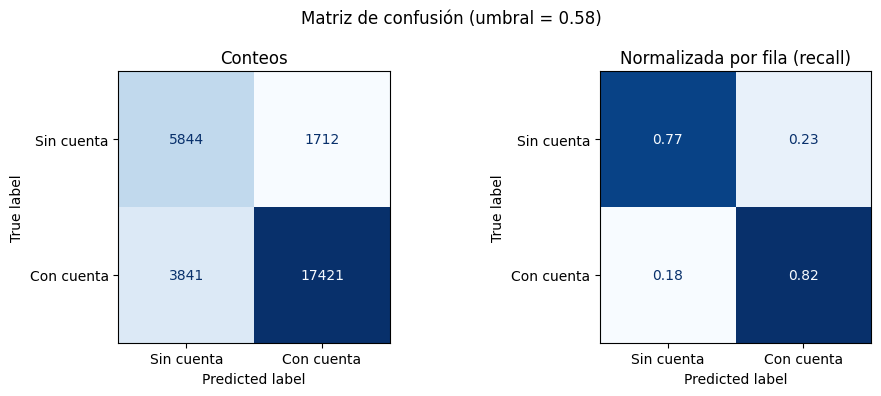

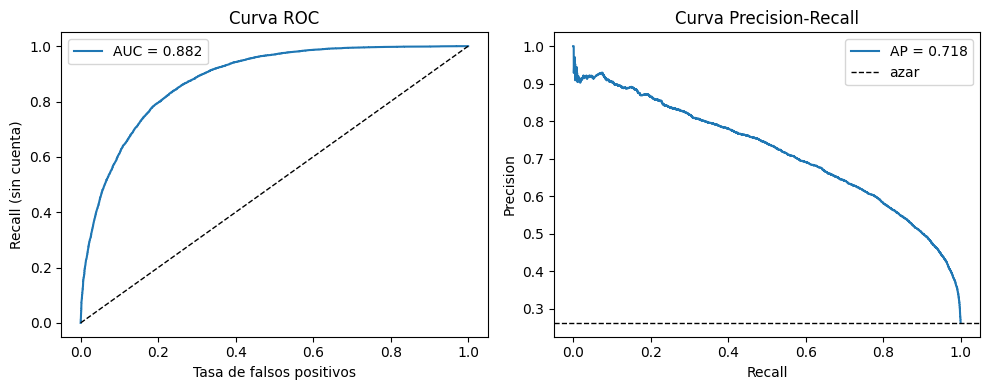

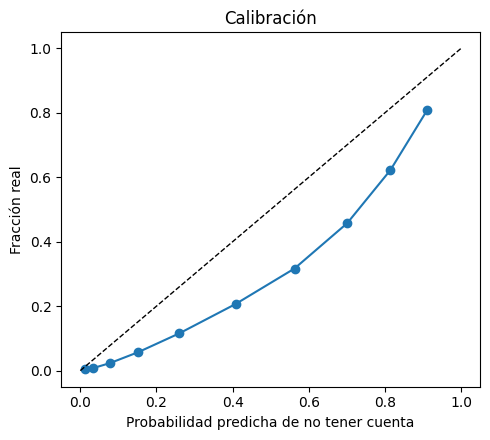

In [26]:
p0_test = p_sin_cuenta(pipe_final, X_test)
m_test = metricas(y_test, p0_test, umbral)
guardar_json(m_test, TABLES_DIR / "metricas_test.json")
display(pd.Series(m_test, name="test").round(4).to_frame())

# ---------- 9.1 matriz de confusión ----------
y_pred = predecir_clase(p0_test, umbral)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for ax, norm, titulo in zip(ejes, [None, "true"], ["Conteos", "Normalizada por fila (recall)"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=[0, 1], normalize=norm),
                           display_labels=["Sin cuenta", "Con cuenta"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
    ax.set_title(titulo)
fig.suptitle(f"Matriz de confusión (umbral = {umbral:.2f})"); fig.tight_layout()
fig.savefig(FIGURES_DIR / "matriz_confusion.png", dpi=150); plt.show()

# ---------- 9.2 ROC y Precision-Recall ----------
y_excl = (np.asarray(y_test) == POS_LABEL).astype(int)
fpr, tpr, _ = roc_curve(y_excl, p0_test)
prec, rec, _ = precision_recall_curve(y_excl, p0_test)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_excl, p0_test):.3f}")
ejes[0].plot([0, 1], [0, 1], "k--", lw=1)
ejes[0].set(xlabel="Tasa de falsos positivos", ylabel="Recall (sin cuenta)", title="Curva ROC"); ejes[0].legend()
ejes[1].plot(rec, prec, label=f"AP = {average_precision_score(y_excl, p0_test):.3f}")
ejes[1].axhline(y_excl.mean(), color="k", ls="--", lw=1, label="azar")
ejes[1].set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall"); ejes[1].legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR / "roc_pr.png", dpi=150); plt.show()

# ---------- 9.3 calibración ----------
frac, media = calibration_curve(y_excl, p0_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(media, frac, "o-"); ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="Probabilidad predicha de no tener cuenta", ylabel="Fracción real", title="Calibración")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "calibracion.png", dpi=150); plt.show()

,variable,importancia,desv
8,economycode,0.0839,0.0015
7,regionwb,0.0732,0.0010
6,internet_use,0.0307,0.0005
1,educ,0.0248,0.0006
0,age,0.0211,0.0008
4,emp_in,0.0173,0.0007
2,inc_q,0.0076,0.0003
3,female,0.0025,0.0003
5,urban,0.0014,0.0002


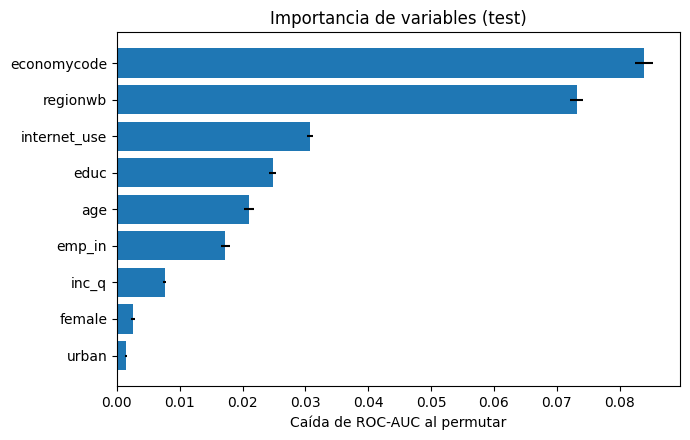

In [27]:
# ---------- 9.4 importancia de variables por permutación ----------
muestra = X_test.sample(min(20000, len(X_test)), random_state=RANDOM_STATE)
y_muestra = (y_test.loc[muestra.index] == POS_LABEL).astype(int)
perm = permutation_importance(
    pipe_final, muestra, y_muestra, n_repeats=5, random_state=RANDOM_STATE,
    scoring=lambda est, X, y: roc_auc_score(y, p_sin_cuenta(est, X)))
importancia = pd.DataFrame({"variable": FEATURES, "importancia": perm.importances_mean,
                            "desv": perm.importances_std}).sort_values("importancia", ascending=False)
importancia.to_csv(TABLES_DIR / "importancia_variables.csv", index=False)
display(importancia.round(4))

top = importancia.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top["variable"], top["importancia"], xerr=top["desv"])
ax.set(xlabel="Caída de ROC-AUC al permutar", title="Importancia de variables (test)")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "importancia_variables.png", dpi=150); plt.show()

In [28]:
# ---------- 9.5 análisis de errores por subgrupos ----------
d = X_test.copy()
d["y"] = y_test.values
d["p0"] = p0_test
d["pred"] = predecir_clase(p0_test, umbral)
d["error"] = (d["pred"] != d["y"]).astype(int)
d["genero"] = d["female"].map({1: "Mujer", 0: "Hombre"})
d["zona"] = d["urban"].map({1: "Urbana", 0: "Rural"})
d["grupo_edad"] = pd.cut(d["age"], [14, 24, 34, 44, 54, 64, 100],
                         labels=["15-24", "25-34", "35-44", "45-54", "55-64", "65+"])

errores = {}
for col in ["genero", "grupo_edad", "inc_q", "educ", "zona", "regionwb", "economycode"]:
    filas = []
    for g, s in d.groupby(col, observed=True):
        if len(s) < 50 or s["y"].nunique() < 2:
            continue
        m = metricas(s["y"], s["p0"].values, umbral)
        filas.append({col: g, "n": len(s), "pct_sin_cuenta_real": (s["y"] == 0).mean(),
                      "pct_error": s["error"].mean(), "recall_sin_cuenta": m["recall_sin_cuenta"],
                      "precision_sin_cuenta": m["precision_sin_cuenta"], "f1_sin_cuenta": m["f1_sin_cuenta"]})
    errores[col] = pd.DataFrame(filas).sort_values("f1_sin_cuenta")
    errores[col].to_csv(TABLES_DIR / f"errores_por_{col}.csv", index=False)

for col in ["genero", "grupo_edad", "inc_q", "educ", "zona", "regionwb"]:
    print(f"\n--- Errores por {col} (peor F1 primero) ---")
    display(errores[col].round(3))
print("\n--- 10 países con peor F1 (mín. 30 personas sin cuenta en test) ---")
pais = errores["economycode"].assign(n_sin_cuenta=lambda x: (x["n"] * x["pct_sin_cuenta_real"]).round())
display(pais[pais["n_sin_cuenta"] >= 30].head(10).round(3))

# errores más "confiados": el modelo estaba muy seguro y se equivocó
(d[d["error"] == 1].assign(confianza=lambda x: (x["p0"] - 0.5).abs())
   .sort_values("confianza", ascending=False).head(100)
   .to_csv(TABLES_DIR / "errores_mas_confiados.csv", index=False))


--- Errores por genero (peor F1 primero) ---


,genero,n,pct_sin_cuenta_real,pct_error,recall_sin_cuenta,precision_sin_cuenta,f1_sin_cuenta
0,Hombre,13733,0.220,0.180,0.727,0.570,0.639
1,Mujer,15085,0.301,0.204,0.804,0.625,0.703



--- Errores por grupo_edad (peor F1 primero) ---


,grupo_edad,n,pct_sin_cuenta_real,pct_error,recall_sin_cuenta,precision_sin_cuenta,f1_sin_cuenta
5,65+,4401,0.207,0.178,0.752,0.551,0.636
1,25-34,5956,0.253,0.187,0.724,0.610,0.662
2,35-44,5422,0.232,0.177,0.747,0.595,0.662
4,55-64,3707,0.230,0.172,0.734,0.604,0.662
3,45-54,4236,0.223,0.173,0.764,0.586,0.663
0,15-24,5096,0.409,0.260,0.855,0.635,0.729



--- Errores por inc_q (peor F1 primero) ---


,inc_q,n,pct_sin_cuenta_real,pct_error,recall_sin_cuenta,precision_sin_cuenta,f1_sin_cuenta
4,5.0,7231,0.175,0.147,0.669,0.566,0.613
3,4.0,6012,0.229,0.178,0.724,0.591,0.650
2,3.0,5545,0.273,0.205,0.783,0.595,0.676
1,2.0,5132,0.314,0.214,0.805,0.623,0.703
0,1.0,4667,0.369,0.234,0.856,0.636,0.730


... (4 outputs left out)


--- Errores por regionwb (peor F1 primero) ---


,regionwb,n,pct_sin_cuenta_real,pct_error,recall_sin_cuenta,precision_sin_cuenta,f1_sin_cuenta
2,High income,9217,0.068,0.065,0.422,0.523,0.467
1,Europe & Central Asia (excluding high income),3578,0.238,0.221,0.598,0.533,0.564
5,South Asia,1375,0.327,0.214,0.719,0.658,0.687
0,East Asia & Pacific (excluding high income),2441,0.277,0.190,0.767,0.630,0.692
6,Sub-Saharan Africa (excluding high income),7067,0.373,0.273,0.824,0.598,0.693
3,Latin America & Caribbean (excluding high income),3093,0.395,0.281,0.841,0.604,0.703
4,Middle East & North Africa (excluding high inc...,2047,0.533,0.298,0.940,0.653,0.771



--- 10 países con peor F1 (mín. 30 personas sin cuenta en test) ---


,economycode,n,pct_sin_cuenta_real,pct_error,recall_sin_cuenta,precision_sin_cuenta,f1_sin_cuenta,n_sin_cuenta
71,LKA,176,0.210,0.239,0.054,0.222,0.087,37.0
52,IND,597,0.119,0.121,0.070,0.455,0.122,71.0
11,BHR,199,0.156,0.146,0.097,0.750,0.171,31.0
107,RUS,208,0.154,0.173,0.188,0.375,0.250,32.0
41,GEO,206,0.180,0.189,0.189,0.438,0.264,37.0
20,CHN,823,0.106,0.124,0.241,0.368,0.292,87.0
108,SAU,199,0.241,0.271,0.333,0.421,0.372,48.0
136,ZMB,202,0.153,0.183,0.387,0.400,0.393,31.0
66,KWT,200,0.260,0.270,0.365,0.475,0.413,52.0
109,SEN,221,0.213,0.231,0.404,0.452,0.427,47.0


## 10. Cómo usa el modelo la app

Como guardamos el **pipeline completo**, la app solo necesita:
1. Cargar `modelo_final.joblib` y `modelo_final_meta.json`.
2. Construir **un DataFrame de una fila** con las columnas de `meta["features"]`, con los valores **ya recodificados** (`female` 1 = mujer / 0 = hombre, `emp_in` 1 = en la fuerza laboral, `urban` 1 = urbano, `internet_use` 0/1). Si el formulario trabaja con los códigos originales de Findex (1/2), hay que pasar antes por `limpiar()` de `src/preprocess.py`.
3. Calcular `P(sin cuenta)` y compararla con `meta["umbral_sin_cuenta"]`.

`.reindex(columns=FEATURES)` garantiza el orden de columnas y convierte en `NaN` lo que falte (el imputador del pipeline lo rellena). Un país o región **no visto** en el entrenamiento no rompe nada (`handle_unknown="ignore"`). Esta es la función que usa la app.

In [29]:
def predecir_perfil(perfil, pipe=None, meta=None):
    """perfil: dict con valores YA recodificados. Devuelve clase, etiqueta y probabilidades."""
    if pipe is None:
        pipe = joblib.load(MODELS_DIR / "modelo_final.joblib")
        meta = json.loads((MODELS_DIR / "modelo_final_meta.json").read_text())
    X = pd.DataFrame([perfil]).reindex(columns=meta["features"])
    p0 = float(p_sin_cuenta(pipe, X)[0])
    clase = int(predecir_clase([p0], meta["umbral_sin_cuenta"])[0])
    return {"account_pred": clase,
            "etiqueta": "Sin cuenta (excluido)" if clase == 0 else "Con cuenta",
            "prob_sin_cuenta": p0, "prob_con_cuenta": 1 - p0}


ejemplo = X_test.iloc[0].to_dict()          # un perfil real del test, como prueba
print("Perfil:", ejemplo)
print("Predicción:", predecir_perfil(ejemplo))
print("Valor real:", int(y_test.iloc[0]), "(0 = sin cuenta, 1 = con cuenta)")

Perfil: {'age': 20, 'educ': 2.0, 'inc_q': 1.0, 'female': 0, 'emp_in': 0.0, 'urban': 0.0, 'internet_use': 1, 'regionwb': 'Latin America & Caribbean (excluding high income)', 'economycode': 'GTM'}
Predicción: {'account_pred': 0, 'etiqueta': 'Sin cuenta (excluido)', 'prob_sin_cuenta': 0.7774309224869557, 'prob_con_cuenta': 0.22256907751304433}
Valor real: 1 (0 = sin cuenta, 1 = con cuenta)
